In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("CyberPulse ML environment is ready!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

CyberPulse ML environment is ready!
Pandas: 3.0.6
NumPy: 2.5.3


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

# Project root is the parent of the notebooks folder
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "feature_time_48k_2048_load_1.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

df.head()

Project root: l:\CyberPulse-IoT
Dataset exists: True

Dataset loaded successfully!
Shape: (2300, 10)
Rows: 2300
Columns: ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'fault']


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,0.35986,-0.41890,0.017840,0.122746,0.124006,-0.118571,-0.042219,2.901946,6.950855,Ball_007_1
1,0.46772,-0.36111,0.022255,0.132488,0.134312,0.174699,-0.081548,3.482334,6.035202,Ball_007_1
2,0.46855,-0.43809,0.020470,0.149651,0.151008,0.040339,-0.274069,3.102819,7.376926,Ball_007_1
3,0.58475,-0.54303,0.020960,0.157067,0.158422,-0.023266,0.134692,3.691097,7.558387,Ball_007_1
4,0.44685,-0.57891,0.022167,0.138189,0.139922,-0.081534,0.402783,3.193561,6.312085,Ball_007_1


In [3]:
# Dataset structure and data types
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumber of unique values per column:")
print(df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 2300 entries, 0 to 2299
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   max       2300 non-null   float64
 1   min       2300 non-null   float64
 2   mean      2300 non-null   float64
 3   sd        2300 non-null   float64
 4   rms       2300 non-null   float64
 5   skewness  2300 non-null   float64
 6   kurtosis  2300 non-null   float64
 7   crest     2300 non-null   float64
 8   form      2300 non-null   float64
 9   fault     2300 non-null   str    
dtypes: float64(9), str(1)
memory usage: 179.8 KB

Missing values per column:
max         0
min         0
mean        0
sd          0
rms         0
skewness    0
kurtosis    0
crest       0
form        0
fault       0
dtype: int64

Duplicate rows: 0

Number of unique values per column:
max         1963
min         1978
mean        2300
sd          2300
rms         2300
skewness    2300
kurtosis    2300
crest       2300
form        2

In [4]:
TARGET = "fault"

assert TARGET in df.columns, (
    f"Target column '{TARGET}' not found."
)

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

print("Feature columns:", X.columns.tolist())
print("Number of features:", X.shape[1])
print("Number of target classes:", y.nunique())

print("\nTarget labels:")
print(sorted(y.astype(str).unique()))

Feature columns: ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form']
Number of features: 9
Number of target classes: 10

Target labels:
['Ball_007_1', 'Ball_014_1', 'Ball_021_1', 'IR_007_1', 'IR_014_1', 'IR_021_1', 'Normal_1', 'OR_007_6_1', 'OR_014_6_1', 'OR_021_6_1']


fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
Normal_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Name: count, dtype: int64


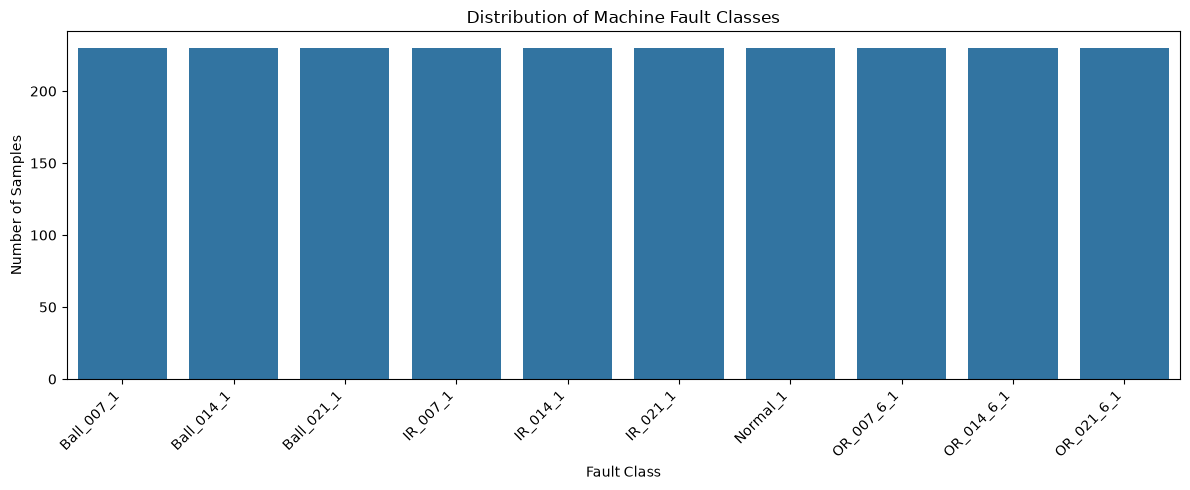

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = y.value_counts().sort_index()

print(class_counts)

plt.figure(figsize=(12, 5))
sns.countplot(
    data=df,
    x=TARGET,
    order=class_counts.index
)

plt.title("Distribution of Machine Fault Classes")
plt.xlabel("Fault Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

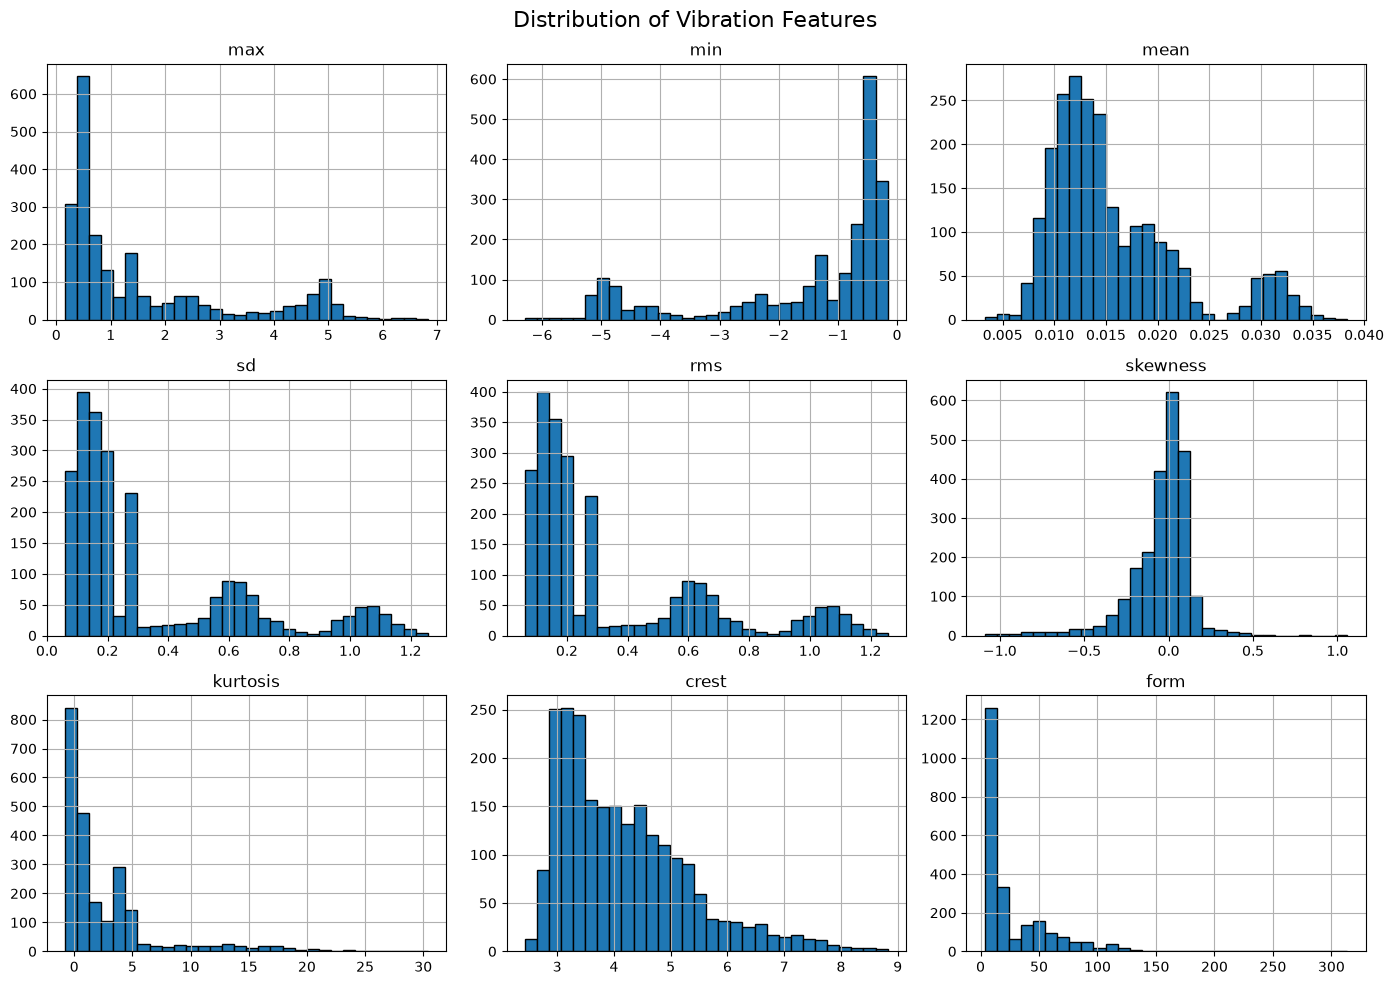

In [6]:
X.hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Vibration Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

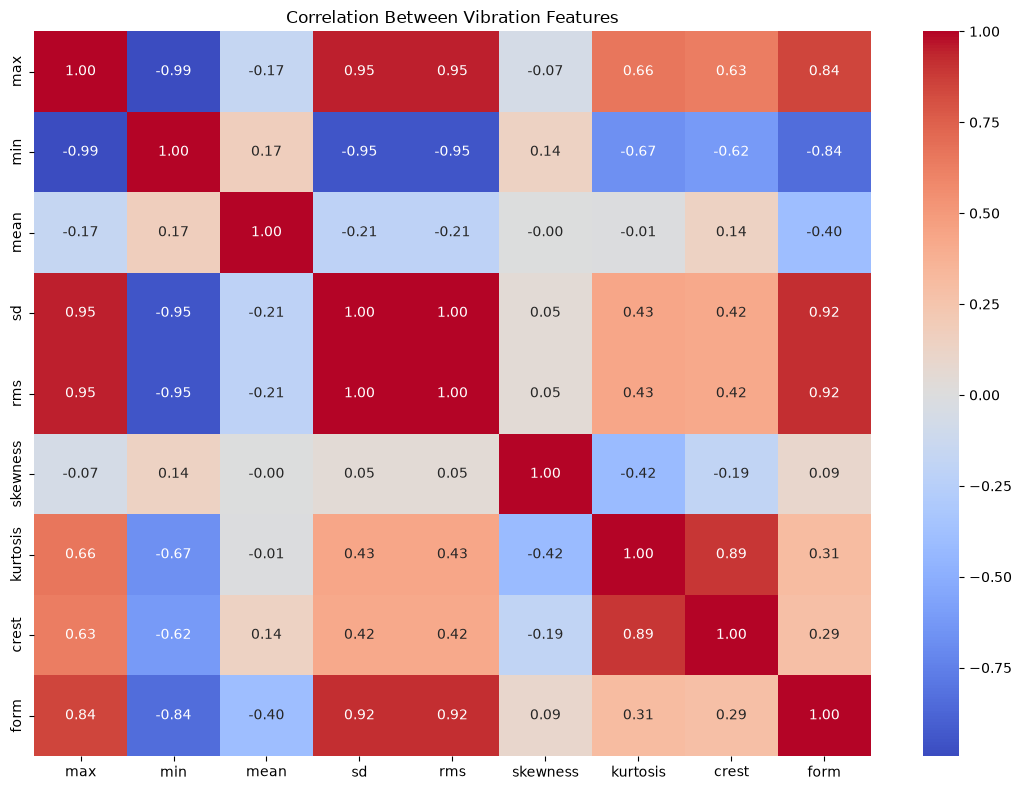

In [7]:
correlation = X.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Vibration Features")
plt.tight_layout()
plt.show()

In [8]:
constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

print("Constant features:", constant_features)

if constant_features:
    print("These features contain no variation.")
else:
    print("No constant features found.")

Constant features: []
No constant features found.


In [9]:
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

class_counts.rename("sample_count").to_csv(
    RESULTS_DIR / "class_distribution.csv"
)

correlation.to_csv(
    RESULTS_DIR / "feature_correlation.csv"
)

print("EDA tables saved to:", RESULTS_DIR)

EDA tables saved to: l:\CyberPulse-IoT\results


In [10]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nClass distribution:")
print(df["fault"].value_counts().sort_index())

print("\nFeature data types:")
print(X.dtypes)

Dataset shape: (2300, 10)

Missing values:
max         0
min         0
mean        0
sd          0
rms         0
skewness    0
kurtosis    0
crest       0
form        0
fault       0
dtype: int64

Duplicate rows: 0

Class distribution:
fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
Normal_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Name: count, dtype: int64

Feature data types:
max         float64
min         float64
mean        float64
sd          float64
rms         float64
skewness    float64
kurtosis    float64
crest       float64
form        float64
dtype: object


In [11]:
# Confirm all classes and their sample counts
print("Number of classes:", df["fault"].nunique())
print(df["fault"].value_counts().sort_index())

# Define features and target
TARGET = "fault"

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

# Validate the input data
assert X.shape[1] == 9, "Unexpected number of features"
assert X.select_dtypes(include="number").shape[1] == 9
assert y.notna().all(), "Missing target labels detected"

print("\nFeatures:", X.columns.tolist())
print("Target:", TARGET)
print("Dataset preparation complete.")

Number of classes: 10
fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
Normal_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Name: count, dtype: int64

Features: ['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form']
Target: fault
Dataset preparation complete.


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())

Training samples: 1840
Testing samples: 460

Training class distribution:
fault
Ball_007_1    184
Ball_014_1    184
Ball_021_1    184
IR_007_1      184
IR_014_1      184
IR_021_1      184
Normal_1      184
OR_007_6_1    184
OR_014_6_1    184
OR_021_6_1    184
Name: count, dtype: int64

Testing class distribution:
fault
Ball_007_1    46
Ball_014_1    46
Ball_021_1    46
IR_007_1      46
IR_014_1      46
IR_021_1      46
Normal_1      46
OR_007_6_1    46
OR_014_6_1    46
OR_021_6_1    46
Name: count, dtype: int64


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_lr), 4
))

print("Macro precision:", round(
    precision_score(y_test, y_pred_lr, average="macro"), 4
))

print("Macro recall:", round(
    recall_score(y_test, y_pred_lr, average="macro"), 4
))

print("Macro F1:", round(
    f1_score(y_test, y_pred_lr, average="macro"), 4
))

print("\nClassification report:\n")
print(classification_report(y_test, y_pred_lr, zero_division=0))

Accuracy: 0.9065
Macro precision: 0.9087
Macro recall: 0.9065
Macro F1: 0.9046

Classification report:

              precision    recall  f1-score   support

  Ball_007_1       0.91      0.91      0.91        46
  Ball_014_1       0.91      0.65      0.76        46
  Ball_021_1       0.79      0.74      0.76        46
    IR_007_1       0.96      1.00      0.98        46
    IR_014_1       1.00      1.00      1.00        46
    IR_021_1       0.92      1.00      0.96        46
    Normal_1       0.92      1.00      0.96        46
  OR_007_6_1       1.00      1.00      1.00        46
  OR_014_6_1       0.70      0.80      0.75        46
  OR_021_6_1       0.98      0.96      0.97        46

    accuracy                           0.91       460
   macro avg       0.91      0.91      0.90       460
weighted avg       0.91      0.91      0.90       460



In [15]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# Extra Trees
et_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train, y_train)
y_pred_et = et_model.predict(X_test)

print("Random Forest and Extra Trees trained successfully.")

Random Forest and Extra Trees trained successfully.


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

predictions = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Extra Trees": y_pred_et
}

comparison = []

for name, predictions_for_model in predictions.items():
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions_for_model),
        "Macro Precision": precision_score(
            y_test, predictions_for_model,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions_for_model,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions_for_model,
            average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.9065,0.9087,0.9065,0.9046
1,Random Forest,0.9457,0.9492,0.9457,0.9460
2,Extra Trees,0.9413,0.9445,0.9413,0.9415


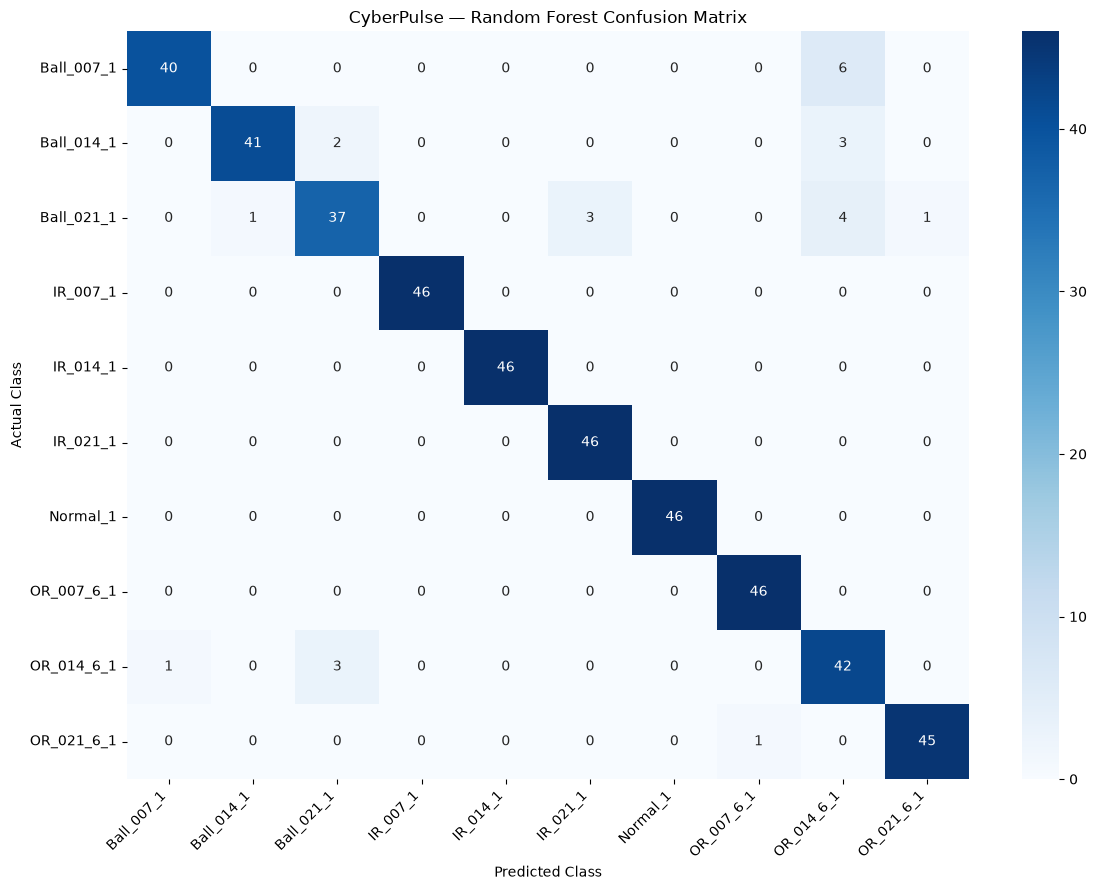

In [18]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

labels = sorted(y.unique())

cm = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=labels
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CyberPulse — Random Forest Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    RESULTS_DIR / "baseline_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")


Model comparison saved successfully.


,Feature,Importance
4,rms,0.204352
3,sd,0.196609
2,mean,0.163090
6,kurtosis,0.115210
0,max,0.088834
1,min,0.086502
8,form,0.076358
7,crest,0.055699
5,skewness,0.013346


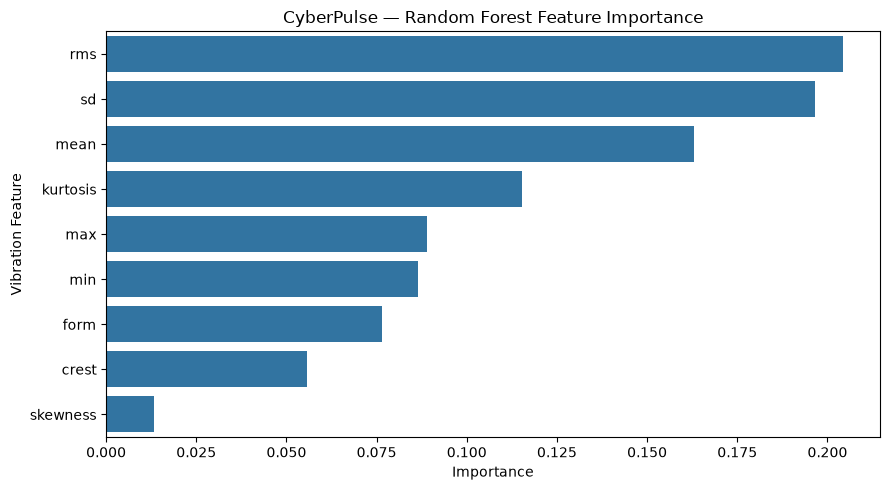

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("CyberPulse — Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Vibration Feature")
plt.tight_layout()
plt.show()

In [21]:
importance_df.to_csv(
    RESULTS_DIR / "random_forest_feature_importance.csv",
    index=False
)

print("Feature importance saved.")

Feature importance saved.


In [22]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns:
['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'fault']

First 5 rows:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,0.35986,-0.41890,0.017840,0.122746,0.124006,-0.118571,-0.042219,2.901946,6.950855,Ball_007_1
1,0.46772,-0.36111,0.022255,0.132488,0.134312,0.174699,-0.081548,3.482334,6.035202,Ball_007_1
2,0.46855,-0.43809,0.020470,0.149651,0.151008,0.040339,-0.274069,3.102819,7.376926,Ball_007_1
3,0.58475,-0.54303,0.020960,0.157067,0.158422,-0.023266,0.134692,3.691097,7.558387,Ball_007_1
4,0.44685,-0.57891,0.022167,0.138189,0.139922,-0.081534,0.402783,3.193561,6.312085,Ball_007_1


In [23]:
print("Dataset shape:", df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["fault"].value_counts().sort_index())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (2300, 10)

All columns:
['max', 'min', 'mean', 'sd', 'rms', 'skewness', 'kurtosis', 'crest', 'form', 'fault']

Class distribution:
fault
Ball_007_1    230
Ball_014_1    230
Ball_021_1    230
IR_007_1      230
IR_014_1      230
IR_021_1      230
Normal_1      230
OR_007_6_1    230
OR_014_6_1    230
OR_021_6_1    230
Name: count, dtype: int64

Data types:
max         float64
min         float64
mean        float64
sd          float64
rms         float64
skewness    float64
kurtosis    float64
crest       float64
form        float64
fault           str
dtype: object

First 5 rows:


,max,min,mean,sd,rms,skewness,kurtosis,crest,form,fault
0,0.35986,-0.41890,0.017840,0.122746,0.124006,-0.118571,-0.042219,2.901946,6.950855,Ball_007_1
1,0.46772,-0.36111,0.022255,0.132488,0.134312,0.174699,-0.081548,3.482334,6.035202,Ball_007_1
2,0.46855,-0.43809,0.020470,0.149651,0.151008,0.040339,-0.274069,3.102819,7.376926,Ball_007_1
3,0.58475,-0.54303,0.020960,0.157067,0.158422,-0.023266,0.134692,3.691097,7.558387,Ball_007_1
4,0.44685,-0.57891,0.022167,0.138189,0.139922,-0.081534,0.402783,3.193561,6.312085,Ball_007_1


In [24]:
# Check exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Check duplicate feature vectors, ignoring the label
print(
    "Duplicate feature rows:",
    df.drop(columns=["fault"]).duplicated().sum()
)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Exact duplicate rows: 0
Duplicate feature rows: 0

Missing values:
max         0
min         0
mean        0
sd          0
rms         0
skewness    0
kurtosis    0
crest       0
form        0
fault       0
dtype: int64


In [25]:
import numpy as np

X = df.drop(columns=["fault"])

corr = X.corr(numeric_only=True)

# Show each feature pair once, excluding self-correlations
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

strong_pairs = (
    upper.stack()
    .rename("correlation")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)

strong_pairs["absolute_correlation"] = (
    strong_pairs["correlation"].abs()
)

display(
    strong_pairs.sort_values(
        "absolute_correlation", ascending=False
    ).head(10)
)


,feature_1,feature_2,correlation,absolute_correlation
31,sd,rms,0.999998,0.999998
1,max,min,-0.992793,0.992793
3,max,sd,0.951709,0.951709
4,max,rms,0.951700,0.951700
12,min,sd,-0.947029,0.947029
13,min,rms,-0.947007,0.947007
35,sd,form,0.920629,0.920629
44,rms,form,0.920397,0.920397
61,kurtosis,crest,0.892333,0.892333
8,max,form,0.844366,0.844366


In [26]:
from pathlib import Path
import joblib
import json
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Project directories
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained model
model_path = MODEL_DIR / "physical_fault_random_forest.joblib"
joblib.dump(rf_model, model_path)

print("Model saved to:", model_path)

Model saved to: l:\CyberPulse-IoT\models\physical_fault_random_forest.joblib


In [27]:

from pathlib import Path
import json
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create results directory
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Generate predictions on the existing test set
y_pred = rf_model.predict(X_test)

# Calculate metrics
metrics = {
    "model": "Random Forest",
    "test_samples": int(len(y_test)),
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "macro_precision": float(
        precision_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "macro_recall": float(
        recall_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "macro_f1": float(
        f1_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "evaluation": "Stratified 80/20 random train/test split"
}

# Save metrics as JSON
with open(RESULTS_DIR / "physical_fault_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Save per-class classification report
report = classification_report(
    y_test, y_pred, output_dict=True, zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "physical_fault_classification_report.csv"
)

# Save confusion matrix
labels = sorted(pd.Series(y_test).unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

pd.DataFrame(
    cm, index=labels, columns=labels
).rename_axis("actual").to_csv(
    RESULTS_DIR / "physical_fault_confusion_matrix.csv"
)

print("Saved evaluation artifacts:")
print("- results/physical_fault_metrics.json")
print("- results/physical_fault_classification_report.csv")
print("- results/physical_fault_confusion_matrix.csv")
print("\nMetrics:")
print(json.dumps(metrics, indent=4))


Saved evaluation artifacts:
- results/physical_fault_metrics.json
- results/physical_fault_classification_report.csv
- results/physical_fault_confusion_matrix.csv

Metrics:
{
    "model": "Random Forest",
    "test_samples": 460,
    "accuracy": 0.9456521739130435,
    "macro_precision": 0.9492148760901399,
    "macro_recall": 0.9456521739130433,
    "macro_f1": 0.9459879904953915,
    "evaluation": "Stratified 80/20 random train/test split"
}


In [28]:

import joblib
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = (
    PROJECT_ROOT / "models" / "physical_fault_random_forest.joblib"
)

# Load the saved model
loaded_model = joblib.load(MODEL_PATH)

# Define the required input feature order
FEATURES = [
    "max", "min", "mean", "sd", "rms",
    "skewness", "kurtosis", "crest", "form"
]

def predict_bearing_fault(feature_values):
    """
    Predict a bearing fault from nine engineered signal features.
    feature_values must be a dictionary with the FEATURES keys.
    """
    missing = set(FEATURES) - set(feature_values)
    extra = set(feature_values) - set(FEATURES)

    if missing or extra:
        raise ValueError(
            f"Missing features: {sorted(missing)}; "
            f"unexpected features: {sorted(extra)}"
        )

    sample = pd.DataFrame(
        [[feature_values[name] for name in FEATURES]],
        columns=FEATURES
    )

    prediction = loaded_model.predict(sample)[0]

    return str(prediction)

print("Prediction function is ready.")


Prediction function is ready.


In [29]:

# Take one actual sample from the dataset
sample_row = df.iloc[0]

# Build the input dictionary using the nine model features
sample_features = {
    feature: float(sample_row[feature])
    for feature in FEATURES
}

# Predict the fault class
predicted_fault = predict_bearing_fault(sample_features)
actual_fault = str(sample_row["fault"])

print("Actual fault:   ", actual_fault)
print("Predicted fault:", predicted_fault)
print("Prediction correct:", predicted_fault == actual_fault)


Actual fault:    Ball_007_1
Predicted fault: Ball_007_1
Prediction correct: True


In [31]:

import json

test_classes = [
    "Normal_1",
    "Ball_014_1",
    "IR_007_1",
    "IR_014_1",
    "OR_007_6_1",
]

for fault_class in test_classes:
    row = df[df["fault"] == fault_class].iloc[0]

    sample = {
        feature: float(row[feature])
        for feature in FEATURES
    }

    print(f"\n# Dataset class: {fault_class}")
    print(json.dumps(sample, indent=2))



# Dataset class: Normal_1
{
  "max": 0.20423,
  "min": -0.19881,
  "mean": 0.0080019581445312,
  "sd": 0.0664609306028792,
  "rms": 0.066924807548965,
  "skewness": -0.277749809521948,
  "kurtosis": -0.182979226306964,
  "crest": 3.05163372865251,
  "form": 8.3635538127256
}

# Dataset class: Ball_014_1
{
  "max": 1.0022,
  "min": -0.95483,
  "mean": 0.0135128165527344,
  "sd": 0.151705996046103,
  "rms": 0.152269720550521,
  "skewness": -0.351581357463355,
  "kurtosis": 9.01767491361339,
  "crest": 6.58174190099391,
  "form": 11.2685404968152
}

# Dataset class: IR_007_1
{
  "max": 1.5481,
  "min": -1.4762,
  "mean": 0.0210025201660156,
  "sd": 0.280502948822692,
  "rms": 0.281219827275686,
  "skewness": -0.098845525392233,
  "kurtosis": 4.76337537066629,
  "crest": 5.50494613056697,
  "form": 13.3898134629924
}

# Dataset class: IR_014_1
{
  "max": 0.7168,
  "min": -0.73704,
  "mean": 0.0286796502978516,
  "sd": 0.206346308137513,
  "rms": 0.208279933728737,
  "skewness": -0.0077991